# Clasificación de la función de la cita: SciBERT/SPECTER × Entrada A/B (A4, issue #103)

## 1. Alcance y aviso

> **TODOS los resultados de este notebook son PROVISIONALES.** Las etiquetas de entrenamiento son de **Haiku** y el conjunto de evaluación es un subconjunto de 2015 etiquetado también por Haiku (`gold_eval_2015_haiku.jsonl`). **No es Gold humano:** el Gold v2 no está congelado (#100). Nada de aquí puede citarse como resultado final.
>
> Además, la intersección A/B conserva solo ~54 % de los casos (bloqueo de cobertura, sección 7): no es una muestra aleatoria.

El notebook **solo lee la evidencia versionada** en `proyecto_de_grado/docs/evidencias_clasificacion_a4/` (sin torch, sin GPU). Con 3 semillas la desviación es indicativa; **no hay prueba de significación**.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "proyecto_de_grado").is_dir())
E = RAIZ / "proyecto_de_grado/docs/evidencias_clasificacion_a4"
SEMILLAS = (42, 1234, 2026)
CELDAS = [("scibert", "A"), ("scibert", "B"), ("specter", "A"), ("specter", "B")]
ABLACIONES = ["B_sin_seccion", "B_barajada"]
comp = json.loads((E / "comparacion.json").read_text(encoding="utf-8"))
man_ent = json.loads((E / "manifiesto_entradas.json").read_text(encoding="utf-8"))

# Encoder = matiz (azul SciBERT, naranja SPECTER); entrada = claridad (A clara, B oscura).
COLOR = {("scibert", "A"): "#8bb8ee", ("scibert", "B"): "#2a78d6",
         ("specter", "A"): "#f4ae91", ("specter", "B"): "#eb6834"}
GRIS, INK, INK2 = "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "text.color": INK, "axes.grid": True, "grid.color": "#e5e4e0",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})

def leer(corrida, nombre):
    return json.loads((E / corrida / nombre).read_text(encoding="utf-8"))

def nom(enc, ent, sem):
    return f"{enc}_{ent}_{sem}"

assert comp["estado"] == "provisional_etiquetas_haiku_no_gold_humano"
for adv in comp["advertencias"]:
    print("AVISO:", adv)
mans = {(e, i, s): leer(nom(e, i, s), "manifiesto.json") for e, i in CELDAS for s in SEMILLAS}
sucios = [k for k, m in mans.items() if m["git"]["dirty"]]
print("estado:", comp["estado"], "| n eval:", comp["procedencia"]["gold_n"],
      "| corridas:", len(comp["procedencia"]["corridas"]), "| manifiestos con codigo sucio:", len(sucios),
      "(los generados antes del fix de `dirty` lo incluian por error: ver README del paquete)")

AVISO: Etiquetas Haiku: no es Gold humano; el Gold v2 no esta congelado (#100).
AVISO: Con 3 semillas la desviacion es indicativa; no hay prueba de significacion.
AVISO: La intersección A/B excluye ~46% de los casos (parrafos largos): no es una muestra aleatoria.
estado: provisional_etiquetas_haiku_no_gold_humano | n eval: 732 | corridas: 18 | manifiestos con codigo sucio: 11 (los generados antes del fix de `dirty` lo incluian por error: ver README del paquete)


## 2. Matriz 2×2: F1 macro y micro (media ± desviación entre 3 semillas)

Los cuatro modelos comparten hiperparámetros, semillas, división de entrenamiento y los **mismos 732 IDs de eval** (intersección controlada). Micro-F1 coincide con accuracy porque cada caso tiene una sola etiqueta.

n       F1 macro       F1 micro P macro R macro
encoder entrada                                                   
scibert A        732  0.467 ± 0.033  0.610 ± 0.015   0.473   0.486
        B        732  0.472 ± 0.029  0.611 ± 0.018   0.482   0.493
specter A        732  0.330 ± 0.032  0.539 ± 0.026   0.391   0.343
        B        732  0.302 ± 0.044  0.526 ± 0.046   0.343   0.316

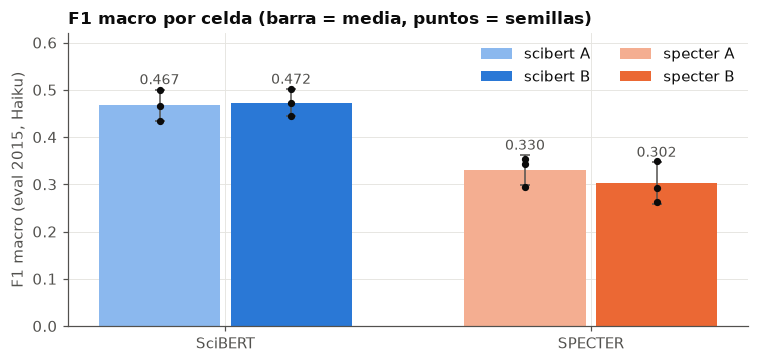

In [2]:
filas = []
for enc, ent in CELDAS:
    a = comp["celdas"][f"{enc}|{ent}"]["agregado"]
    filas.append({"encoder": enc, "entrada": ent, "n": comp["celdas"][f"{enc}|{ent}"]["n"],
                  "F1 macro": f"{a['f1_macro']['media']:.3f} ± {a['f1_macro']['desv']:.3f}",
                  "F1 micro": f"{a['f1_micro']['media']:.3f} ± {a['f1_micro']['desv']:.3f}",
                  "P macro": f"{a['precision_macro']['media']:.3f}", "R macro": f"{a['recall_macro']['media']:.3f}"})
display(pd.DataFrame(filas).set_index(["encoder", "entrada"]))

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(2); w = 0.36
for j, (enc, ent) in enumerate(CELDAS):
    a = comp["celdas"][f"{enc}|{ent}"]["agregado"]["f1_macro"]
    por_sem = [json.loads((E / nom(enc, ent, s) / "metricas_eval.json").read_text())["f1_macro"] for s in SEMILLAS]
    xi = (0 if enc == "scibert" else 1) + (-w / 2 if ent == "A" else w / 2)
    ax.bar(xi, a["media"], w * 0.92, color=COLOR[(enc, ent)], label=f"{enc} {ent}")
    ax.errorbar(xi, a["media"], yerr=a["desv"], fmt="none", ecolor=INK2, capsize=3, lw=1)
    ax.scatter([xi] * 3, por_sem, s=14, color=INK, zorder=3)
    ax.text(xi, a["media"] + a["desv"] + 0.012, f"{a['media']:.3f}", ha="center", fontsize=9, color=INK2)
ax.set_xticks(x, ["SciBERT", "SPECTER"]); ax.set_ylabel("F1 macro (eval 2015, Haiku)")
ax.set_ylim(0, 0.62); ax.set_title("F1 macro por celda (barra = media, puntos = semillas)")
ax.legend(frameon=False, ncol=2, loc="upper right")
plt.tight_layout(); plt.show()

## 3. Deltas: entrada A→B, encoder y ablaciones de sección

Cada delta se calcula **por semilla** (mismos casos) y se resume como media ± desviación. Un delta cuya media no supera su desviación **no distingue un efecto de ruido**.

,factor,delta F1 macro,desv,|media| > desv
contraste,,,,
scibert|A->B,entrada,0.0054,0.0044,True
specter|A->B,entrada,-0.0274,0.0237,True
SciBERT->SPECTER|A,encoder,-0.1371,0.0121,True
SciBERT->SPECTER|B,encoder,-0.1699,0.0164,True
B->B_sin_seccion,ablacion,-0.0091,0.0381,False
B->B_barajada,ablacion,0.0064,0.0076,False
scibert|B->B_con_eval_barajado,sondeo_secciones_barajadas,0.0035,0.0022,True
specter|B->B_con_eval_barajado,sondeo_secciones_barajadas,0.0021,0.0023,False


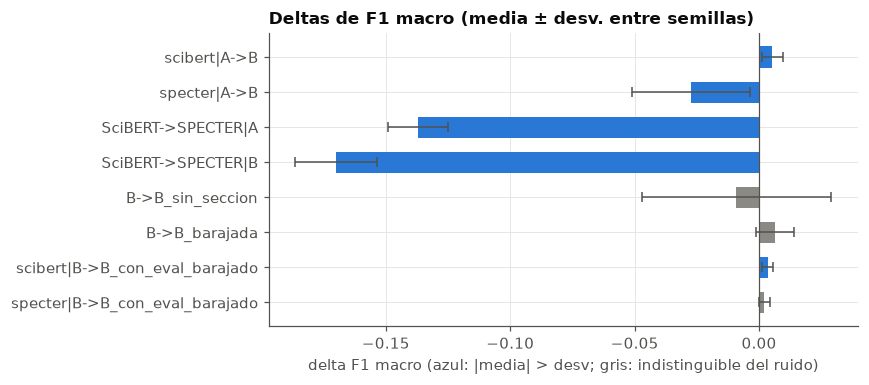

In [3]:
def fila_delta(d):
    a = d["agregado"]["f1_macro"]
    return {"contraste": d["nombre"], "factor": d["factor"], "delta F1 macro": round(a["media"], 4),
            "desv": round(a["desv"], 4), "|media| > desv": abs(a["media"]) > a["desv"]}
deltas = pd.DataFrame([fila_delta(d) for d in comp["deltas"]])
display(deltas.set_index("contraste"))

sel = deltas.copy()
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(sel))
ax.barh(y, sel["delta F1 macro"], xerr=sel["desv"], color=[GRIS if not s else "#2a78d6" for s in sel["|media| > desv"]],
        error_kw={"ecolor": INK2, "capsize": 3, "lw": 1}, height=0.6)
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(y, sel["contraste"]); ax.invert_yaxis()
ax.set_xlabel("delta F1 macro (azul: |media| > desv; gris: indistinguible del ruido)")
ax.set_title("Deltas de F1 macro (media ± desv. entre semillas)")
plt.tight_layout(); plt.show()

**Lectura.** El contraste A→B es nulo dentro de cada encoder (en SPECTER incluso desfavorable a B); la diferencia entre encoders es la única mayor que la dispersión. Las ablaciones de sección (`B_sin_seccion`, `B_barajada`, y el sondeo con eval barajado) no se distinguen de B: **no hay evidencia de que `perfil_seccion` aporte señal, pero tampoco de que no la aporte** (ver amenazas a la validez en el informe).

## 4. Por clase: P/R/F1 (media de semillas) y soporte

scibert A               scibert B  \
                                 soporte precision recall     f1 precision   
Background                           279     0.773  0.708  0.739     0.791   
Gap                                   31     0.185  0.247  0.212     0.207   
Basis                                 42     0.169  0.214  0.188     0.127   
Comparison                           111     0.639  0.480  0.547     0.643   
Application                          128     0.723  0.818  0.765     0.735   
Improvement / Modification            14     0.260  0.262  0.259     0.284   
Evidence                              97     0.526  0.543  0.533     0.552   
Identification of the Originator       7     0.206  0.476  0.273     0.180   
Further Reading                       23     0.776  0.623  0.688     0.819   

                                               specter A                \
                                 recall     f1 precision recall     f1   
Background                        0.688  0.734     0.685  0.695  0.690   
Gap                               0.290  0.241     0.087  0.065  0.073   
Basis                             0.183  0.146     0.103  0.095  0.099   
Comparison                        0.592  0.615     0.479  0.480  0.480   
Application                       0.805  0.768     0.634  0.742  0.683   
Improvement / Modification        0.262  0.267     0.252  0.119  0.153   
Evidence                          0.502  0.525     0.425  0.409  0.416   
Identification of the Originator  0.524  0.265     0.140  0.381  0.200   
Further Reading                   0.594  0.688     0.717  0.101  0.175   

                                 specter B                
                                 precision recall     f1  
Background                           0.686  0.740  0.711  
Gap                                  0.100  0.065  0.076  
Basis                                0.130  0.095  0.108  
Comparison                           0.445  0.393  0.417  
Application                          0.645  0.695  0.667  
Improvement / Modification           0.091  0.095  0.083  
Evidence                             0.394  0.354  0.373  
Identification of the Originator     0.116  0.333  0.163  
Further Reading                      0.481  0.072  0.123

Desviacion del F1 por clase entre semillas (las clases raras son inestables):


,scibert A,scibert B,specter A,specter B
Background,0.005,0.023,0.013,0.027
Gap,0.046,0.032,0.060,0.013
Basis,0.032,0.016,0.065,0.014
Comparison,0.084,0.020,0.059,0.051
Application,0.028,0.015,0.051,0.059
Improvement / Modification,0.085,0.117,0.031,0.087
Evidence,0.002,0.025,0.036,0.028
Identification of the Originator,0.089,0.060,0.042,0.120
Further Reading,0.038,0.038,0.042,0.053


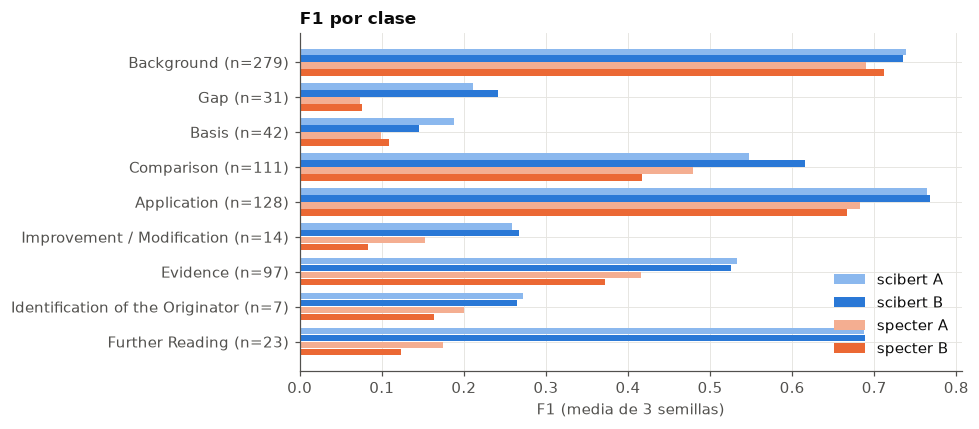

In [4]:
CLASES = [r["label"] for r in leer("scibert_A_42", "metricas_eval.json")["per_class"]]
soporte = {r["label"]: r["support"] for r in leer("scibert_A_42", "metricas_eval.json")["per_class"]}
por_clase = {}
for enc, ent in CELDAS:
    rows = [leer(nom(enc, ent, s), "metricas_eval.json")["per_class"] for s in SEMILLAS]
    for k in ("precision", "recall", "f1"):
        por_clase[(f"{enc} {ent}", k)] = [np.mean([r[i][k] for r in rows]) for i in range(len(CLASES))]
tabla = pd.DataFrame(por_clase, index=CLASES)
tabla.columns = pd.MultiIndex.from_tuples(tabla.columns)
tabla.insert(0, ("", "soporte"), [soporte[c] for c in CLASES])
display(tabla.round(3))

dispersion = pd.DataFrame({f"{e} {i}": [np.std([leer(nom(e, i, s), "metricas_eval.json")["per_class"][k]["f1"]
                                              for s in SEMILLAS], ddof=1) for k in range(len(CLASES))]
                           for e, i in CELDAS}, index=CLASES)
print("Desviacion del F1 por clase entre semillas (las clases raras son inestables):")
display(dispersion.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
yy = np.arange(len(CLASES)); h = 0.2
for j, (enc, ent) in enumerate(CELDAS):
    ax.barh(yy + (j - 1.5) * h, tabla[(f"{enc} {ent}", "f1")], h * 0.9, color=COLOR[(enc, ent)], label=f"{enc} {ent}")
ax.set_yticks(yy, [f"{c} (n={soporte[c]})" for c in CLASES]); ax.invert_yaxis()
ax.set_xlabel("F1 (media de 3 semillas)"); ax.set_title("F1 por clase")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 5. Matrices de confusión 9×9

Suma de las 3 semillas, normalizada por fila (recall por clase en la diagonal). Las filas de las clases raras (Further Reading, Identification of the Originator, Improvement / Modification) tienen muy pocos casos.

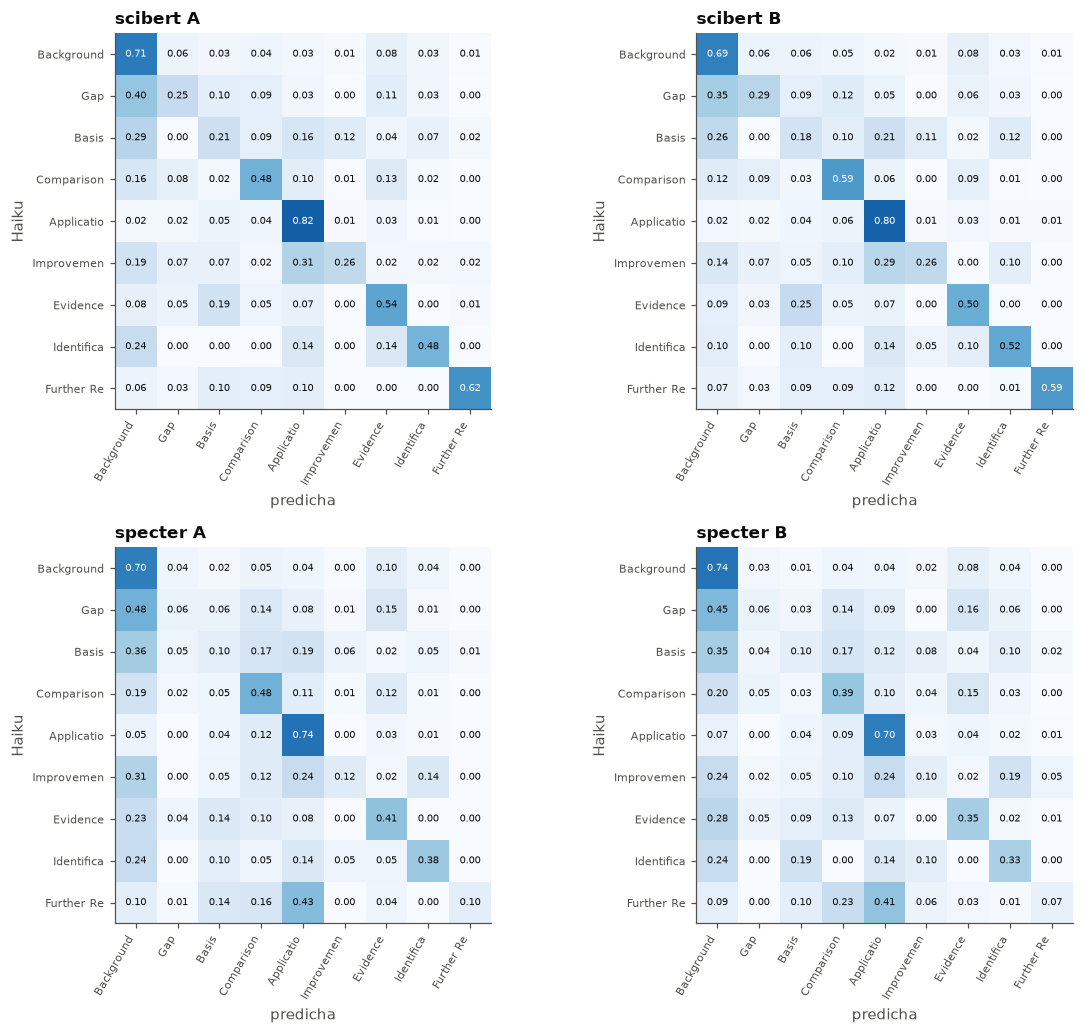

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(11, 9.5))
for ax, (enc, ent) in zip(axs.ravel(), CELDAS):
    cm = sum(np.array(leer(nom(enc, ent, s), "metricas_eval.json")["confusion_matrix"]) for s in SEMILLAS).astype(float)
    norm = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(9), [c[:10] for c in CLASES], rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(9), [c[:10] for c in CLASES], fontsize=7)
    for i in range(9):
        for j in range(9):
            ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if norm[i, j] > 0.55 else INK)
    ax.grid(False); ax.set_title(f"{enc} {ent}"); ax.set_xlabel("predicha"); ax.set_ylabel("Haiku")
plt.tight_layout(); plt.show()

## 6. Ablaciones de sección (SciBERT, refs #128)

`perfil_seccion` es una **heurística por palabras clave, no una etiqueta retórica validada**. Se compara B con la sección del chunk citado frente a: sin sección (`B_sin_seccion`), secciones barajadas en entrenamiento y eval (`B_barajada`) y el **sondeo gratuito** (modelo B evaluado con secciones barajadas, sin reentrenar).

,F1 macro,desv
entrada,,
B,0.4723,0.0287
B_sin_seccion,0.4632,0.0221
B_barajada,0.4787,0.0309
"B (eval barajado, sin reentrenar)",0.4758,0.0308


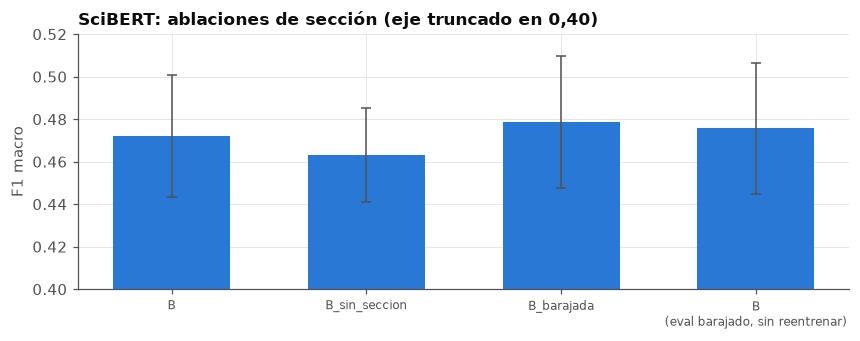

In [6]:
filas = []
for ent in ["B"] + ABLACIONES:
    a = comp["celdas"][f"scibert|{ent}"]["agregado"]
    filas.append({"entrada": ent, "F1 macro": a["f1_macro"]["media"], "desv": a["f1_macro"]["desv"]})
bar = [leer(nom("scibert", "B", s), "metricas_eval_B_barajada.json")["f1_macro"] for s in SEMILLAS]
filas.append({"entrada": "B (eval barajado, sin reentrenar)", "F1 macro": float(np.mean(bar)),
              "desv": float(np.std(bar, ddof=1))})
ab = pd.DataFrame(filas)
display(ab.round(4).set_index("entrada"))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(len(ab)), ab["F1 macro"], yerr=ab["desv"], color="#2a78d6", width=0.6, capsize=3, error_kw={"ecolor": INK2, "lw": 1})
ax.set_xticks(range(len(ab)), [e.replace(" (", "\n(") for e in ab["entrada"]], fontsize=8)
ax.set_ylim(0.40, 0.52); ax.set_ylabel("F1 macro"); ax.set_title("SciBERT: ablaciones de sección (eje truncado en 0,40)")
plt.tight_layout(); plt.show()

## 7. Cobertura, truncamiento y estrato «citado visto en train»

La Entrada B exige texto de chunks del citado. Los párrafos de más de 300 palabras se descartan en la extracción de A1, por lo que la **intersección A/B pierde ~46 %** de los candidatos y no es una muestra aleatoria: puede sesgar las clases.

In [7]:
cob = man_ent["cobertura"]
tab = pd.DataFrame({k: {"candidatos": v["candidatos"], "interseccion": v["interseccion"], "cobertura %": v["cobertura_pct"],
                        **{f"excl. {m}": n for m, n in v["excluidos_por_motivo"].items()}}
                    for k, v in cob.items()}).T
display(tab.fillna(0).astype({"candidatos": int, "interseccion": int}))
for b in man_ent["bloqueos_cobertura"]:
    print(f"BLOQUEO cobertura: {b['conjunto']} {b['cobertura_pct']} % < umbral {b['umbral_pct']} %")

ev = cob["eval_2015"]
cl = pd.DataFrame({"candidatos": ev["por_clase_candidatos"], "interseccion": ev["por_clase_interseccion"]})
cl["conservado %"] = (100 * cl["interseccion"] / cl["candidatos"]).round(1)
print("Eval 2015: clases conservadas por la intersección")
display(cl)

print("Truncamiento en eval 2015 (fraccion de casos con recorte; media de la celda, semilla 42):")
trunc = {}
for enc, ent in CELDAS[:2]:
    t = mans[(enc, ent, 42)]["truncamiento_eval"]["eval_2015"]
    trunc[f"{enc} {ent}"] = {"longitud media": round(t["longitud_media"], 1),
                             **{s: round(v["frac_truncado"], 3) for s, v in t["segmentos"].items()}}
display(pd.DataFrame(trunc).T.fillna("-"))
for enc in ("scibert", "specter"):
    t = mans[(enc, "A", 42)]["tokenizer"]
    print(f"tokenizer {enc}: {t['clase']}, vocab {t['vocab_size']} tokens, sha {t['vocab_sha256'][:12]}")
print("vocabularios identicos:", mans[("scibert", "A", 42)]["tokenizer"]["vocab_sha256"]
      == mans[("specter", "A", 42)]["tokenizer"]["vocab_sha256"], "(vocabularios distintos: los ids y el truncamiento pueden diferir algo entre encoders)")

,candidatos,interseccion,cobertura %,excl. menos_de_3_chunks,excl. parrafo_largo,excl. ValueError,excl. ocl_404,excl. autocita
eval_2015,1363,732,53.71,2.0,629.0,0.0,0.0,0.0
gold_v2,1533,839,54.73,1.0,693.0,0.0,0.0,0.0
train,2245,1241,55.28,0.0,991.0,8.0,5.0,0.0
val,397,213,53.65,0.0,181.0,1.0,1.0,1.0


BLOQUEO cobertura: train 55.28 % < umbral 60.0 %
BLOQUEO cobertura: eval_2015 53.71 % < umbral 60.0 %
BLOQUEO cobertura: gold_v2 54.73 % < umbral 60.0 %
Eval 2015: clases conservadas por la intersección


,candidatos,interseccion,conservado %
Application,260,128,49.2
Background,526,279,53.0
Basis,78,42,53.8
Comparison,181,111,61.3
Evidence,192,97,50.5
Further Reading,37,23,62.2
Gap,47,31,66.0
Identification of the Originator,21,7,33.3
Improvement / Modification,21,14,66.7


Truncamiento en eval 2015 (fraccion de casos con recorte; media de la celda, semilla 42):


,longitud media,abstract,contexto,titulo,chunk_1,chunk_2,chunk_3
scibert A,237.4,0.01,0.0,0.0,-,-,-
scibert B,477.1,-,0.0,-,0.363,0.389,0.396


tokenizer scibert: BertTokenizer, vocab 31090 tokens, sha f0a650346e51
tokenizer specter: BertTokenizer, vocab 31116 tokens, sha f99aae27d5a5
vocabularios identicos: False (vocabularios distintos: los ids y el truncamiento pueden diferir algo entre encoders)


In [8]:
# Estrato: ¿el artículo citado del caso de eval aparece en el train de la intersección?
gold = pd.DataFrame([json.loads(l) for l in (E / "gold_eval_2015_haiku.jsonl").read_text(encoding="utf-8").splitlines()])
tr_ids = set((E / "ids_interseccion_train.txt").read_text().split())
top3_tr = pd.read_csv(E / "top3_train.csv")
citados_train = set(top3_tr.loc[top3_tr.context_id.isin(tr_ids), "cited_id"])
gold["visto"] = gold["cited_id"].isin(citados_train)
print(f"casos de eval con citado visto en train: {gold.visto.sum()} de {len(gold)} ({100 * gold.visto.mean():.1f} %)")

def f1_macro(y, p):
    fs = []
    for c in CLASES:
        tp = sum(a == c and b == c for a, b in zip(y, p)); fp = sum(a != c and b == c for a, b in zip(y, p))
        fn = sum(a == c and b != c for a, b in zip(y, p))
        fs.append(0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn))
    return float(np.mean(fs))   # clases sin soporte ni predicciones cuentan 0 (igual que el paquete)

filas = []
for enc, ent in CELDAS:
    r = {"celda": f"{enc} {ent}"}
    for etiqueta, mascara in (("visto", gold.visto), ("no visto", ~gold.visto)):
        ids = gold.loc[mascara]
        vals = []
        for s in SEMILLAS:
            pred = {json.loads(l)["case_id"]: json.loads(l)["pred_label"]
                    for l in (E / nom(enc, ent, s) / "predicciones_eval.jsonl").read_text().splitlines()}
            vals.append(f1_macro(list(ids["gold"]), [pred[i] for i in ids["id"]]))
        r[f"{etiqueta} (n={len(ids)})"] = f"{np.mean(vals):.3f} ± {np.std(vals, ddof=1):.3f}"
    filas.append(r)
display(pd.DataFrame(filas).set_index("celda"))

casos de eval con citado visto en train: 87 de 732 (11.9 %)


,visto (n=87),no visto (n=645)
celda,,
scibert A,0.325 ± 0.019,0.455 ± 0.031
scibert B,0.343 ± 0.042,0.472 ± 0.028
specter A,0.194 ± 0.023,0.336 ± 0.031
specter B,0.198 ± 0.037,0.309 ± 0.044


Solo ~12 % de los casos de eval citan un artículo visto en train, y el F1 macro del estrato «visto» se calcula sobre ~87 casos y 9 clases: **es ruidoso y no permite concluir** que haya memorización del artículo. Aun así, todas las celdas rinden menos en ese estrato, lo que merece revisarse con el Gold v2.

## 8. Limitaciones

- Etiquetas **Haiku** en train y en eval; **no es Gold humano** (#100 sin congelar). Cualquier cifra es provisional.
- **3 semillas**: desviación indicativa, sin prueba de significación ni intervalos bootstrap.
- Intersección A/B de 732 casos (53,7 % de los candidatos de eval): excluye párrafos largos y no es aleatoria; hay clases con muy poco soporte (Identification of the Originator: 7; Improvement / Modification: 14).
- `perfil_seccion` es una heurística; las ablaciones de sección no tienen potencia para detectar efectos pequeños.
- SPECTER con la misma cabeza `[CLS]` y los mismos hiperparámetros que SciBERT: no se ajustaron por encoder, por lo que la brecha puede reflejar hiperparámetros y no solo el encoder.
- La fuente de etiquetas «Jurado» no se ejecutó (DVC sin descargar): celdas declaradas no ejecutadas.